# Pipeline và data leakage

Bảng đăng ký của câu lạc bộ có vài ô thiếu số đăng ký, một cột ghi buổi sáng hoặc chiều, và một số dự báo mưa chưa được nhập. Ta cần điền thiếu và biến chữ thành số trước khi học. Một thành viên xử lý cả bảng rồi mới chia train/validation để đỡ viết lại. Các con số của validation đã tham gia bước xử lý ấy; điểm còn đo được một buổi chưa thấy không?

Bài này ghép việc tiền xử lý và mô hình thành Pipeline. Mục tiêu không chỉ là code ngắn hơn. Ta muốn mỗi lần đánh giá học đúng những thứ được phép học từ train, rồi áp dụng nguyên cách biến đổi đó cho dữ liệu mới.

> **Sau bài này, có thể**
>
> - Phân biệt biến đổi cố định với những đại lượng phải học từ train.
> - Viết Pipeline và ColumnTransformer cho bảng có số, chữ và dữ liệu thiếu.
> - Kiểm tra scaler, encoder và model được học lại trong mỗi fold.
> - Tìm leakage từ feature chỉ có sau lúc dự đoán, preprocessing toàn bảng và lựa chọn theo test.

## Tiền xử lý cũng là một phần của mô hình

Giả sử train có số đăng ký 10 và 20. Chuẩn hóa bằng trung bình $\mu=15$, độ lệch chuẩn $\sigma=5$ cho hai giá trị $-1$ và $1$. Validation có số đăng ký 30 phải được biến đổi thành $(30-15)/5=3$. Nếu chuẩn hóa validation riêng, 30 là giá trị duy nhất nên lại thành 0: ta đã đổi hệ tọa độ.

Chuẩn hóa dùng

$$z_j=\frac{x_j-\mu_j}{\sigma_j}.$$

$\mu_j$ và $\sigma_j$ là các con số **được học**, dù không dùng nhãn. Giá trị điền thiếu bằng median, danh sách từ trong văn bản, PCA và chọn feature cũng có phần phải học. Chúng thuộc quy trình train, không phải thao tác vô hại đứng ngoài mô hình. Trong scikit-learn: `scaler.fit_transform(X_train)` rồi `scaler.transform(X_test)`; gọi `fit_transform` trên test là học lại μ, σ từ chính test.

Min-max đưa mỗi cột về $[0, 1]$ bằng $(x-\min)/(\max-\min)$, nên cần một cặp min, max cho mỗi cột, tính trên train. Giá trị test ngoài khoảng của train sẽ ra ngoài $[0, 1]$: train có tuổi 20–60 thì tuổi 70 thành $(70-20)/(60-20)=1{,}25$, chuyện bình thường chứ không phải lỗi. Vì dựa vào cực trị, min-max dễ bị một điểm ngoại lai làm lệch cả thang; z-score chỉ dùng μ và σ.



Một biến đổi cố định như đổi cm sang m bằng chia 100 thường không cần fit. Tuy vậy, nó vẫn phải áp dụng nhất quán cho cả train và dữ liệu mới. Còn việc chọn chia 100 sau khi thấy test score cũng là một quyết định có thể làm mất tính độc lập của test.

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

small_train = np.array([[10.0], [20.0]])
small_valid = np.array([[30.0]])
scaler = StandardScaler().fit(small_train)
print('Train:', scaler.transform(small_train).ravel())
print('Valid dùng scaler train:', scaler.transform(small_valid).ravel())
wrong_valid = StandardScaler().fit_transform(small_valid)
print('Valid fit riêng, cách sai:', wrong_valid.ravel())

Train: [-1.  1.]
Valid dùng scaler train: [3.]
Valid fit riêng, cách sai: [0.]


Nhìn hai cách biến đổi 30. Cách đúng giữ quan hệ cao hơn trung bình train ba độ lệch chuẩn. Cách fit riêng đưa một buổi rất đông về ngay trung tâm thang đo, làm model nhận một ý nghĩa khác.

**Hỏi nhanh.** Ta cần điền các ô thiếu ở validation bằng median. Median ấy phải tính từ đâu?

- A. Từ chính các hàng validation
- B. Từ train của lần học đang đánh giá
- C. Từ train và validation gộp lại, trước khi chia
- D. Từ test, vì test giống dữ liệu lúc dùng thật nhất

<details><summary>Đáp án</summary>

B. Từ train của lần học đang đánh giá

Median cũng là thứ được học từ dữ liệu, giống trọng số của mô hình, nên chỉ được tính từ train của lần đang đánh giá. Tính từ validation hay test là đã dùng chính dữ liệu đang chấm để chuẩn bị bài làm.

</details>

## Data leakage: thông tin vượt qua ranh giới

Rò rỉ dữ liệu (data leakage) xuất hiện khi quy trình xây mô hình dùng thông tin không được phép có trong tình huống đang đánh giá. Có nhiều đường đi, và không phải đường nào Pipeline cũng chặn được.

| Đường rò rỉ | Ví dụ ở câu lạc bộ | Cách chặn |
|---|---|---|
| Feature có sau lúc dự đoán | Số vé đã quét sau buổi | Kiểm thời điểm cột được biết |
| Preprocessing | Median tính trên toàn bảng | Fit trong Pipeline và từng fold |
| Mẫu gần trùng | Một phiếu lưu hai lần | Gom bản trùng, chia group đúng |
| Nhãn tương lai | Tổng tham gia tuần sau trong feature tuần này | Kiểm lag/cửa sổ/thời điểm |
| Quyết định theo test | Chọn model vì test đẹp hơn | Dùng validation, giữ test độc lập |

Một phép biến đổi dùng feature của test, dù không dùng nhãn, vẫn có thể làm sai phép đánh giá: lúc dùng thật, dữ liệu mới chưa tồn tại khi fit. Có những đề cho phép dùng toàn bộ input không nhãn của tập test (cách làm transductive); khi ấy đề sẽ nói rõ. Mặc định trong khóa học là không gộp dữ liệu cần dự đoán vào bước học tiền xử lý.

Bước nào học từ nhãn cũng phải nằm trong từng fold: chọn 50 đặc trưng tương quan nhất với nhãn trên toàn bảng rồi mới kiểm định chéo có thể cho 92%, trong khi chọn lại bên trong từng fold chỉ còn 78%. Với mô hình ngôn ngữ lớn, bộ câu hỏi đánh giá đã có trên mạng từ lâu có thể đã lọt vào dữ liệu huấn luyện, nên điểm cao có thể là nhớ đáp án. Điểm tốt bất thường so với độ khó của bài, như 99,99% ở một bài nổi tiếng là khó, là tín hiệu kiểm leakage trước tiên, rồi kiểm xem lớp có lệch cực mạnh không.



**Hỏi nhanh.** Cột `final_attendance` chỉ có sau khi buổi sinh hoạt kết thúc. Đặt cột này vào Pipeline thì nó có thành feature hợp lệ không?

- A. Không, lúc dự đoán vẫn chưa có cột này
- B. Có, vì Pipeline tự chặn mọi kiểu rò rỉ
- C. Có, miễn là không gọi `fit` trên test
- D. Không, vì Pipeline chỉ nhận cột số

<details><summary>Đáp án</summary>

A. Không, lúc dự đoán vẫn chưa có cột này

Pipeline chỉ lo thứ tự các bước và chỗ gọi `fit`. Nó không biết một cột có sẵn vào lúc nào hay mang ý nghĩa gì. Cột chữ vẫn vào Pipeline được qua bước mã hóa, nên lý do không nằm ở kiểu dữ liệu.

</details>

## Bảng có số, chữ và ô thiếu

Ta tạo 80 buổi giả. Cột `slot` là sáng hoặc chiều; target tăng thêm năm người cho buổi chiều theo công thức giả lập. Một số feature được che thành missing sau khi sinh target để mô phỏng việc ghi chép thiếu. Ta giữ 60 buổi đầu làm train, 20 buổi cuối làm validation.

In [ ]:
import pandas as pd

rng = np.random.default_rng(14)
n = 80
registered = rng.integers(15, 65, size=n).astype(float)
rain = rng.uniform(0, 1, size=n)
slot = rng.choice(['sang', 'chieu'], size=n)
y = 4 + 0.7 * registered - 5 * rain + 5 * (slot == 'chieu')
y = y + rng.normal(0, 1.5, size=n)
X = pd.DataFrame({'registered': registered, 'rain': rain, 'slot': slot})
X.loc[[2, 13, 44, 64], 'registered'] = np.nan
X.loc[[6, 50, 75], 'rain'] = np.nan
X_train, X_valid = X.iloc[:60], X.iloc[60:]
y_train, y_valid = y[:60], y[60:]
print(X_train.isna().sum().to_dict())
print(X_valid.isna().sum().to_dict())

{'registered': 3, 'rain': 2, 'slot': 0}
{'registered': 1, 'rain': 1, 'slot': 0}


Missing là thiếu thông tin, không mặc nhiên là giá trị 0. Đăng ký chưa ghi lại khác với chắc chắn không ai đăng ký. Median là baseline có thể dùng cho cột số; nó không khôi phục chính xác dữ liệu bị mất. Có thể thêm cột chỉ báo missing nếu validation đúng cách cho thấy hữu ích.

Với chữ, one-hot encoding tạo một cột cho mỗi danh mục đã thấy: sáng thành vector đánh dấu sáng, chiều thành vector đánh dấu chiều. Không mã hóa sáng=0, chiều=1, tối=2 rồi mặc nhiên coi khoảng cách giữa chúng có ý nghĩa: với mã 1, 2, 3, mô hình tuyến tính coi danh mục thứ hai nằm “giữa” hai danh mục kia. Ô thiếu ở cột chữ có thể điền bằng danh mục gặp nhiều nhất trong train, hoặc thêm hẳn một danh mục “thiếu”. Bài 2.11 (Feature engineering) sẽ mở rộng phần này.

**Hỏi nhanh.** Thay vì one-hot, ta mã hóa `slot` thành sáng = 0, chiều = 1, tối = 2, rồi đưa vào `LinearRegression`. Làm vậy là ngầm giả định điều gì?

- A. Không giả định gì, vì số chỉ là tên của từng buổi
- B. Đủ dữ liệu thì mô hình sẽ tự học ra thứ tự đúng
- C. Cách mã hóa chỉ ảnh hưởng khi cột có ô thiếu
- D. Sáng, chiều, tối nằm trên một đường thẳng, cách đều nhau

<details><summary>Đáp án</summary>

D. Sáng, chiều, tối nằm trên một đường thẳng, cách đều nhau

Cột số này được nhân với một hệ số $w$, nên sáng đóng góp 0, chiều đóng góp $w$, tối đóng góp $2w$. So với buổi sáng, buổi tối bị ép phải lệch đúng gấp đôi buổi chiều, trong khi dữ liệu chưa hề nói vậy. One-hot cho mỗi buổi một hệ số riêng, nên không áp đặt thứ tự nào.

</details>



## Ghép ColumnTransformer với Pipeline

ColumnTransformer chọn các nhóm cột và áp dụng những nhánh biến đổi khác nhau. Pipeline trong nhánh số điền thiếu rồi chuẩn hóa. Nhánh chữ điền danh mục thiếu rồi one-hot. Pipeline ngoài ghép toàn bộ tiền xử lý với `LinearRegression`. Cột số có vài giá trị cực lớn, như thu nhập, thì trung vị an toàn hơn trung bình khi điền thiếu, và có thể chặn (clip) theo ngưỡng tính trên train trước khi chuẩn hóa.



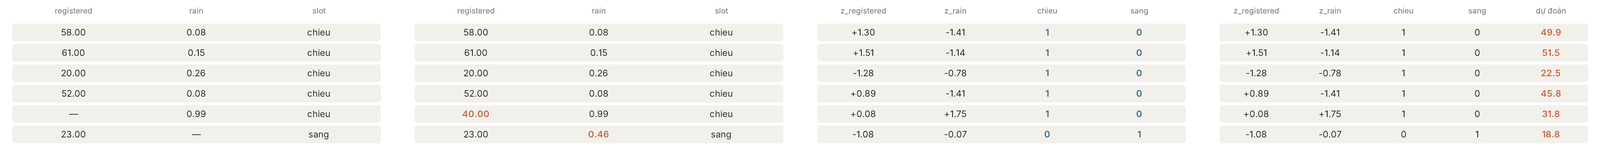

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

numeric = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
category = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocess = ColumnTransformer([
    ('num', numeric, ['registered', 'rain']),
    ('cat', category, ['slot']),
])
model = Pipeline([
    ('preprocess', preprocess),
    ('regressor', LinearRegression()),
])
model.fit(X_train, y_train)
prediction = model.predict(X_valid)
print('Sau biến đổi:', model.named_steps['preprocess'].transform(X_valid).shape)
print(f'Validation MAE={mean_absolute_error(y_valid, prediction):.3f}')

Sau biến đổi: (20, 4)
Validation MAE=1.707


Nhìn shape sau biến đổi: hai cột số cộng hai cột one-hot. Tên `preprocess` và `regressor` do ta đặt để tra thành phần và chỉnh tham số sau này. Khi gọi `model.fit`, mọi bước cần fit đều học trên `X_train`; khi gọi `predict`, chỉ transform theo trạng thái đã lưu rồi dự đoán.

`sparse_output=False` giúp ví dụ nhỏ dễ nhìn dạng mảng đầy. Khi một cột có hàng nghìn danh mục, giữ mặc định mảng thưa để tiết kiệm bộ nhớ.

**Hỏi nhanh.** Imputer nằm trong Pipeline, nhưng giá trị median đã được tính sẵn từ toàn bảng rồi truyền cố định vào. Chạy cross-validation thì còn sai ở đâu?

- A. Median ấy đã tính cả các hàng validation của từng fold
- B. Chỉ sai khi mô hình phía sau không tuyến tính
- C. Không sai, vì mỗi fold vẫn gọi `fit` trên Pipeline
- D. Phải dùng mean thay cho median thì mới đúng

<details><summary>Đáp án</summary>

A. Median ấy đã tính cả các hàng validation của từng fold

Con số median ấy đã được tính khi nhìn cả các hàng validation, và đặt nó vào Pipeline không xóa được điều đó. Median phải được tính lại từ train của từng fold, nghĩa là để imputer tự `fit` bên trong Pipeline.

</details>

## Đọc trạng thái đã học và thử danh mục mới

Có thể kiểm trực tiếp median đã lưu. Đây là cách đối chiếu quy trình, tương tự in trạng thái nhỏ khi debug một thuật toán.

In [ ]:
fitted_numeric = model.named_steps['preprocess'].named_transformers_['num']
medians = fitted_numeric.named_steps['impute'].statistics_
print('Median đã học:', np.round(medians, 3))
print('Median tính từ train:', np.round(X_train[['registered', 'rain']].median().to_numpy(), 3))
new_session = pd.DataFrame({'registered': [30.0], 'rain': [0.2], 'slot': ['toi']})
new_features = model.named_steps['preprocess'].transform(new_session)
print('Cột one-hot của danh mục chưa thấy:', new_features[0, 2:])
print('Dự đoán buổi mới:', np.round(model.predict(new_session), 3))

Median đã học: [40.     0.462]
Median tính từ train: [40.     0.462]
Cột one-hot của danh mục chưa thấy: [0. 0.]
Dự đoán buổi mới: [27.493]


`handle_unknown='ignore'` đưa danh mục chưa thấy thành toàn số 0 trong nhóm cột ấy. Code chạy được, nhưng không có nghĩa mô hình đã học được tác động của buổi tối. Dự đoán ấy dùng phần số và cách mở rộng ngầm của model; cần kiểm các danh mục mới trong đánh giá thực tế. Không thay buổi tối bằng buổi chiều chỉ để encoder nhận nếu hai loại khác nhau về ý nghĩa. Không đặt tham số này thì `OneHotEncoder` báo lỗi khi gặp danh mục lạ. Gọi `pd.get_dummies` riêng cho train và test còn tệ hơn: train có `city_HN, city_HCM, city_DN`, test có `city_HN, city_HUE`, hai bảng lệch cột; hãy fit một bộ mã hóa trên train rồi transform test.

**Hỏi nhanh.** Buổi “toi” chưa từng có trong train, nên nhận vector one-hot `[0, 0]` và được dự đoán 27.49 người. Con số này thực chất là dự đoán cho cái gì?

- A. Mô hình đã học được buổi tối đông hay vắng
- B. Một buổi không phải sáng, cũng không phải chiều
- C. Mô hình coi buổi tối như buổi chiều vì gần nhau
- D. Không có nghĩa gì, lẽ ra phải báo lỗi

<details><summary>Đáp án</summary>

B. Một buổi không phải sáng, cũng không phải chiều

Với `LinearRegression`, mỗi cột one-hot cộng thêm một hệ số riêng vào dự đoán. Vector toàn 0 thì bỏ qua cả hai hệ số ấy, chỉ còn phần của các cột số và hệ số chặn. Kết quả là dự đoán cho một buổi “trung tính” mà dữ liệu chưa từng có. Code chạy được, nhưng con số này là đoán mò. Nếu buổi tối xuất hiện thật, ta phải thu thêm dữ liệu rồi học lại.

</details>

## Cùng Pipeline, fit lại trong mỗi fold

Muốn CV theo thời gian, chuyển **toàn Pipeline** cho `cross_val_score`, không chuyển bảng đã transform từ toàn bộ dữ liệu. Công cụ tạo bản mô hình mới và fit từ train của từng fold. Muốn dò tham số của một bước trong Pipeline, gọi bằng tên bước, hai dấu gạch dưới, rồi tên tham số, như `regressor__fit_intercept`; `make_pipeline` tự đặt tên bước theo tên lớp viết thường, nên tham số `C` của `SVC` là `svc__C`.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

cv = TimeSeriesSplit(n_splits=3, test_size=10)
scores = cross_val_score(
    model, X_train, y_train, cv=cv,
    scoring='neg_mean_absolute_error', n_jobs=1,
)
print('Fold MAE:', np.round(-scores, 3))
print(f'Mean CV MAE={-scores.mean():.3f}')

Fold MAE: [1.087 1.995 1.314]
Mean CV MAE=1.465


Hàm chấm của scikit-learn theo quy ước điểm càng lớn càng tốt, nên MAE được đưa vào dưới tên `neg_mean_absolute_error`, tức MAE mang dấu âm; lấy `-scores` để đọc lại MAE. Chỉ `X_train` được đưa vào CV này; 20 buổi validation bên ngoài vẫn chưa tham gia fit lần nào. Đó là cách bố trí hay dùng: CV bên trong để chọn tham số, holdout bên ngoài để kiểm lại phương án đã chọn. Ba fold chênh nhau (1.09 đến 2.00) là tín hiệu nên xem số mẫu và ô thiếu của từng fold, chưa phải bằng chứng leakage.

**Hỏi nhanh.** Muốn cross-validation không bị rò rỉ qua bước điền median, ta đưa gì vào `cross_val_score`?

- A. Bảng đã điền median tính từ mọi hàng
- B. Chỉ đưa regressor, còn scaler đã fit trên toàn bảng
- C. Bảng mà mỗi fold validation tự điền median của nó
- D. Pipeline gồm imputer, scaler và regressor

<details><summary>Đáp án</summary>

D. Pipeline gồm imputer, scaler và regressor

Đưa cả Pipeline vào thì ở mỗi fold, imputer, scaler và regressor đều được fit lại chỉ trên train của fold ấy. Điền median từ toàn bảng, hay từ chính fold validation, đều là lấy thông tin của phần đang chấm.

</details>

## Ví dụ tính tay: điểm hoàn hảo có thể vô dụng

Giả sử train có target $(20,30)$, validation target là 40. Một cột log sau buổi ghi đúng số người đã vào cửa. Mô hình $\hat y=x_{\rm final\_count}$ cho lỗi 0 trên cả ba hàng. Phép tính không sai; hợp đồng dự đoán sai vì cột ấy chưa có chiều thứ Sáu.

Code dưới cố tình mô phỏng đường tắt này, để nhìn vì sao điểm gần 0 không đủ bảo đảm tính hợp lệ. Nó không phải phương án dùng thật.

In [ ]:
hindsight_model = LinearRegression().fit(y_train.reshape(-1, 1), y_train)
hindsight_prediction = hindsight_model.predict(y_valid.reshape(-1, 1))
print(f'MAE dùng chính target làm feature, cách sai={mean_absolute_error(y_valid, hindsight_prediction):.6f}')

MAE dùng chính target làm feature, cách sai=0.000000


Feature availability phải được kiểm trước khi vui với metric. Pipeline không nhận ra cột chính là target nếu người viết đã đổi tên nó. Tương tự, target encoding, chọn feature theo tương quan với nhãn, hoặc imputation dùng nhãn cũng cần thực hiện đúng bên trong từng fold; một lớp Pipeline thường không tự giải quyết cách tạo những feature phức tạp đó.

## Bẫy cài đặt

Đừng `fit_transform` validation rồi gọi `predict`: model cần cùng phép transform đã học từ train. Đừng lấy `model.named_steps['preprocess']` đã fit trên toàn train để transform trước một CV bên trong; đó vẫn là nhìn vào fold validation.

Kiểm tên cột, dtype và ý nghĩa đơn vị của dữ liệu mới. Một cột số đọc thành chuỗi có thể đi sai nhánh. Một ID số đi qua scaler cũng không vì thế trở thành feature có ích. Nếu lưu model để dùng lại, phải lưu cùng trạng thái tiền xử lý và recipe dựng cột, không chỉ hệ số regressor.

## Khi đi thi

- **Lập bảng feature**: mỗi cột biết được lúc nào, tính từ đâu.
- **Gói mọi bước học từ dữ liệu vào một Pipeline**, giữ phép chia cố định rồi mới thử tham số.
- **Điểm nhảy vọt sau khi thêm một cột** thì truy nguồn cột ấy trước khi mừng.
- **Chạy thử đường inference** với một mẫu không có nhãn và một danh mục chưa thấy.

## Tóm tắt

- Median, thang đo và encoder đều có trạng thái học từ train.
- ColumnTransformer xử lý các nhóm cột; Pipeline giữ thứ tự fit/transform/model.
- CV phải fit lại toàn quy trình theo từng fold.
- Leakage từ thời điểm feature, bản gần trùng và lựa chọn theo test cần kiểm ngoài cơ chế Pipeline.

## Kiểm tra cuối bài

**Câu 1.** Bảng dữ liệu cho vay có cột số (thu nhập, tuổi) và cột chữ (nghề nghiệp, học vấn). 15% số dòng có ô thiếu, và cột thu nhập có vài giá trị cực lớn. Chuỗi tiền xử lý nào hợp lý nhất?

- A. Xóa mọi dòng có ô thiếu, đưa cột số về khoảng 0 đến 1 theo min và max, đổi cột chữ thành 0, 1, 2…
- B. Điền 0 vào ô thiếu, xóa dòng có thu nhập quá xa trung bình, giữ nguyên thang cột số, đổi cột chữ thành 0, 1, 2…
- C. Điền median cho cột số và giá trị hay gặp nhất cho cột chữ, chặn bớt giá trị cực lớn, chuẩn hóa cột số, one-hot cột chữ
- D. Giữ nguyên ô thiếu, chuẩn hóa cột số, one-hot cột chữ, rồi đưa thẳng vào `LinearRegression`

<details><summary>Đáp án</summary>

C. Điền median cho cột số và giá trị hay gặp nhất cho cột chữ, chặn bớt giá trị cực lớn, chuẩn hóa cột số, one-hot cột chữ

Xóa dòng thiếu là mất 15% dữ liệu. Đưa về 0 đến 1 theo min và max thì một giá trị cực lớn ép mọi giá trị khác dồn về gần 0. Đổi chữ thành 0, 1, 2 tạo ra một thứ tự giả. Điền 0 làm sai nghĩa “không biết”. `LinearRegression` thì không chạy được khi còn ô thiếu. Chuỗi nào cũng vậy, median, giá trị hay gặp nhất, ngưỡng chặn, trung bình và độ lệch chuẩn đều phải học từ train, nên cả chuỗi phải nằm trong Pipeline.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 304](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=117)

</details>
**Câu 2.** Thao tác nào phải học một con số từ train trước khi dùng?

- A. Đổi cm sang m, tức chia cho 100
- B. Điền ô thiếu bằng median
- C. Đổi tên cột theo một danh sách cố định
- D. Nhân một cột với hằng số mà đề đã cho

<details><summary>Đáp án</summary>

B. Điền ô thiếu bằng median

Median thay đổi theo dữ liệu, nên phải tính từ train rồi giữ nguyên khi xử lý validation và test. Ba thao tác còn lại dùng hằng số hoặc quy tắc cố định, không học gì từ dữ liệu.

</details>
**Câu 3.** Bảng có cột tuổi là số và cột loại trường là chữ. ColumnTransformer chuẩn hóa cột tuổi, one-hot cột loại trường, rồi ghép kết quả lại. Cách tổ chức này bảo đảm được điều gì?

- A. Các cột không được chỉ định luôn được giữ lại, bất kể `remainder`
- B. Mỗi nhánh nhận đúng nhóm cột của nó, rồi các đầu ra được ghép lại
- C. Scaler và encoder dùng chung một bộ trung bình và phương sai
- D. Encoder tự chọn những loại trường liên quan nhất đến nhãn

<details><summary>Đáp án</summary>

B. Mỗi nhánh nhận đúng nhóm cột của nó, rồi các đầu ra được ghép lại

ColumnTransformer chỉ chia cột cho từng nhánh rồi ghép kết quả lại. Cột không được chỉ định có giữ hay không là do tham số `remainder`. Mỗi nhánh fit riêng, nên không dùng chung trung bình hay phương sai, và không nhánh nào tự chọn feature theo nhãn.

</details>
**Câu 4.** OneHotEncoder đã học hai loại A và B, với `drop=None` và `handle_unknown="ignore"`. Gặp loại C chưa từng thấy, nhóm cột này sẽ cho vector nào?

- A. (1, 0)
- B. (0, 1)
- C. (1, 1)
- D. (0, 0)

<details><summary>Đáp án</summary>

D. (0, 0)

Encoder chỉ có hai cột cho A và B đã học, khi transform không thêm cột cho C. Với `handle_unknown="ignore"`, loại lạ nhận toàn số 0. Nếu có dùng `drop` thì phải kiểm thêm, vì loại bị bỏ cũng có mã toàn 0, và hai trường hợp sẽ trùng nhau.

</details>
**Câu 5.** Một mô hình được học lại mỗi tuần. Sau 6 tuần, có người cần dựng lại đúng mô hình của tuần 3, nhưng nhóm chỉ còn file mô hình mới nhất. Muốn dựng lại được một mô hình đã học, ta cần lưu những gì?

- A. Dữ liệu đã dùng, cấu hình, seed, phiên bản thư viện, và cả Pipeline đã fit
- B. File mô hình và đoạn code huấn luyện
- C. Code, điểm validation và nhật ký huấn luyện
- D. File mô hình, các tham số đã chọn và điểm trên test

<details><summary>Đáp án</summary>

A. Dữ liệu đã dùng, cấu hình, seed, phiên bản thư viện, và cả Pipeline đã fit

Mô hình chỉ có nghĩa khi đi cùng đúng phép biến đổi đầu vào đã học. Thiếu median, trung bình, độ lệch chuẩn hay danh sách loại của encoder, thì cùng một hàng dữ liệu sẽ được đưa vào mô hình dưới một dạng khác. Lưu nguyên Pipeline đã fit là giữ được phần này. Còn dữ liệu, seed và phiên bản thư viện quyết định việc học lại có ra đúng kết quả cũ hay không.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 308](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=120)

</details>
**Câu 6.** Ta cần dự báo trước buổi sinh hoạt một ngày. Cột `actual_attendance` trong bảng được ghi sau sự kiện, và có nó thì MAE gần bằng 0. Nên xử lý thế nào?

- A. Bỏ cột này khỏi feature, vì lúc dự báo chưa có nó
- B. Giữ cột này, nhưng đặt scaler vào Pipeline
- C. Giữ cột này, nhưng tăng số fold validation
- D. Giữ cột này, miễn là không dùng nó làm nhãn

<details><summary>Đáp án</summary>

A. Bỏ cột này khỏi feature, vì lúc dự báo chưa có nó

Cột này chỉ có sau sự kiện, nên lúc dự báo trước một ngày ta không có nó để đưa vào. MAE gần 0 chính là dấu hiệu rò rỉ. Đặt scaler vào Pipeline, thêm fold, hay không dùng nó làm nhãn đều không thay đổi được việc cột này chưa tồn tại.

</details>
**Câu 7.** Mỗi học sinh được chụp ảnh nhiều lần, và một số ảnh còn bị lưu lại dưới tên khác. Muốn đánh giá trên học sinh mới, ta cần làm gì trước khi chạy cross-validation?

- A. Đặt scaler vào Pipeline, rồi chia ngẫu nhiên từng ảnh
- B. Giữ tỉ lệ nhãn ở hai phía, thay cho việc chia theo học sinh
- C. Tìm các ảnh trùng, rồi chia theo nhóm học sinh
- D. Đổi tên file, rồi chia ngẫu nhiên từng ảnh

<details><summary>Đáp án</summary>

C. Tìm các ảnh trùng, rồi chia theo nhóm học sinh

Chia theo học sinh thì validation toàn là học sinh mới, đúng tình huống cần đo. Tìm ảnh trùng giúp phát hiện cả những bản sao đang mang tên hay thông tin khác. Pipeline hay việc giữ tỉ lệ nhãn đều không tự xử lý được chuyện này.

</details>
**Câu 8.** Scaler fit trên train có mean 10, std 2, và mô hình học trên thang đã chuẩn hóa ấy. Validation có mean 20, std 5. Giá trị $x = 22$ ở validation phải được đưa vào mô hình thành bao nhiêu?

- A. $(22-10)/5 = 2.4$
- B. $(22-10)/2 = 6$
- C. $(22-20)/5 = 0.4$
- D. $22-20 = 2$

<details><summary>Đáp án</summary>

B. $(22-10)/2 = 6$

Validation phải được biến đổi bằng đúng mean và std đã học từ train: $(22-10)/2 = 6$. Fit scaler riêng trên validation thì ra một thang khác với thang mô hình đã học, giống như đổi đơn vị đo giữa chừng.

</details>
**Câu 9.** Một nhóm chọn 20 feature từ cả 100 dòng, rồi mới chạy 5-fold cross-validation, và thấy điểm rất cao. Kiểm lại thế nào cho đáng tin?

- A. Ở mỗi fold, chọn feature trên phần validation
- B. Dùng test để chọn feature, miễn là không fit mô hình trên test
- C. Ở mỗi fold, chỉ chọn feature từ phần train của fold đó
- D. Chọn một lần trên cả 100 dòng, dùng chung cho mọi fold

<details><summary>Đáp án</summary>

C. Ở mỗi fold, chỉ chọn feature từ phần train của fold đó

Chọn feature cũng là học từ dữ liệu, nên phải fit trên phần train của fold rồi mới áp dụng cho phần validation, như mọi bước khác trong Pipeline. Nếu nhìn cả bảng trước khi chia, các hàng validation đã góp phần vào lựa chọn, và điểm sẽ quá lạc quan.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 4](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=5)

</details>
**Câu 10.** Ta đã dùng kết quả trên test để chọn số feature, rồi chấm lại cấu hình thắng trên chính test đó. Muốn báo một con số độc lập, ta phải làm gì?

- A. Fit lại mô hình từ đầu với seed khác rồi chấm lại
- B. Đổi tên test thành validation, giữ nguyên điểm cũ
- C. Bỏ bước chọn feature khỏi Pipeline rồi chấm lại
- D. Chấm trên dữ liệu mới, chưa tham gia quyết định nào

<details><summary>Đáp án</summary>

D. Chấm trên dữ liệu mới, chưa tham gia quyết định nào

Test đã được dùng để chọn số feature, nên giờ nó là dữ liệu để chọn, không còn độc lập. Ta phải chốt quy trình rồi chấm trên dữ liệu chưa từng dùng. Đổi seed hay sửa lại code không xóa được ảnh hưởng của việc đã chọn theo test.

</details>
## Đọc thêm

- [scikit-learn — Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html). Đọc các ví dụ về preprocessing không nhất quán và leakage.
- [scikit-learn — Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html). Tra cách ghép Pipeline, ColumnTransformer và tên bước.
- [scikit-learn — OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html). Xem cách xử lý danh mục mới và lựa chọn mảng thưa.